In [1]:
!find /kaggle/input/datasets/rohanimtiaz/ai651-pa2-code/25280058_PA2 -name "*.py"
!cp /kaggle/input/datasets/rohanimtiaz/ai651-pa2-code/25280058_PA2/*.py /kaggle/working/
%cd /kaggle/working
import torch
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0))

/kaggle/input/datasets/rohanimtiaz/ai651-pa2-code/25280058_PA2/train.py
/kaggle/input/datasets/rohanimtiaz/ai651-pa2-code/25280058_PA2/evaluate.py
/kaggle/input/datasets/rohanimtiaz/ai651-pa2-code/25280058_PA2/figures.py
/kaggle/input/datasets/rohanimtiaz/ai651-pa2-code/25280058_PA2/model.py
/kaggle/input/datasets/rohanimtiaz/ai651-pa2-code/25280058_PA2/utils.py
/kaggle/input/datasets/rohanimtiaz/ai651-pa2-code/25280058_PA2/checks.py
/kaggle/input/datasets/rohanimtiaz/ai651-pa2-code/25280058_PA2/optical_flow.py
/kaggle/input/datasets/rohanimtiaz/ai651-pa2-code/25280058_PA2/Question1/assignment2/widgets.py
/kaggle/input/datasets/rohanimtiaz/ai651-pa2-code/25280058_PA2/Question1/assignment2/evaluation.py
/kaggle/input/datasets/rohanimtiaz/ai651-pa2-code/25280058_PA2/Question1/assignment2/visuals.py
/kaggle/input/datasets/rohanimtiaz/ai651-pa2-code/25280058_PA2/Question1/assignment2/worlds.py
/kaggle/input/datasets/rohanimtiaz/ai651-pa2-code/25280058_PA2/Question1/assignment2/models.py
/k

In [2]:
!python checks.py
!python model.py

| Check | Expected | Yours | Pass |
|---|---|---|---|
| (a) max|M(M(x)) - x| | 0 | 0.0 equal = True | True |
| (b) max|R4(x) - x| | 0 | 0.0 equal = True | True |
| (c) max|MRM(x) - R-1(x)| | 0 | 0.0 equal = True | True |
| (d) bright pixel of M(p) | (7, 10, 43) | (7, 10, 43) | True |
| (e) bright pixel of R(p) | (7, 43, 10) | (7, 43, 10) | True |
| (f) 1x input / target frames | 1-5 / 6-10 | [1, 2, 3, 4, 5] / [6, 7, 8, 9, 10] | True |
| (g) 2x input / target frames | 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19 | [1, 3, 5, 7, 9] / [11, 13, 15, 17, 19] | True |
| (h) 3x input / target frames | 1, 4, 7, 10, 13 / 16, 19 | [1, 4, 7, 10, 13] / [16, 19] | True |
All Table 1 checks passed
baseline parameters: 480784 reach (pixels): 8
D1 parameters: 594496 reach (pixels): 16
D2 parameters: 480784 reach (pixels): 16
All model checks passed


100%|████████████████████████████████████████| 819M/819M [00:51<00:00, 16.0MB/s]
Caption numbers: median speed 3.318 pixels per frame, kept pixels 103050
Speed percentiles (5, 25, 50, 75, 95): [1.414, 3.0, 3.318, 3.886, 4.318]
Direction fractions per 20 degree bin: [0.049, 0.0488, 0.0675, 0.0731, 0.0602, 0.0561, 0.0263, 0.0326, 0.0384, 0.082, 0.0642, 0.0541, 0.0666, 0.0614, 0.0571, 0.0366, 0.0487, 0.0772]
Total variation, mirrored vs original: 0.1321
Total variation, rotated vs original: 0.2
Total variation, original vs uniform: 0.1099


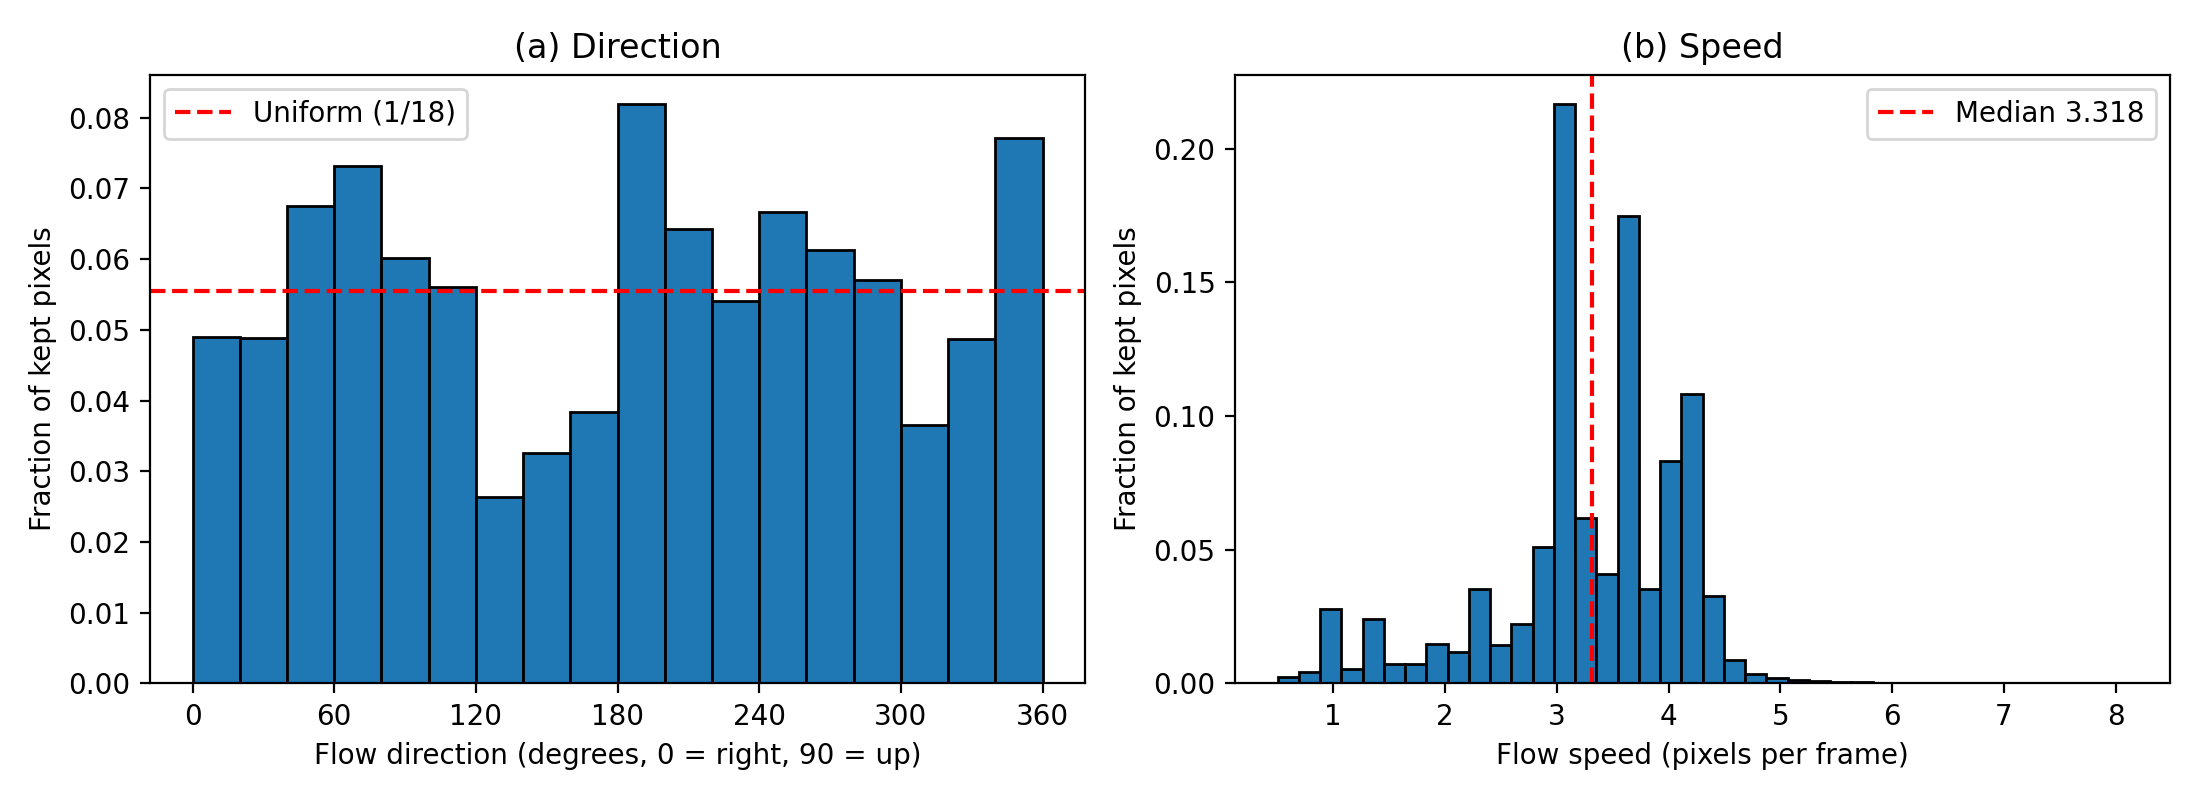

In [3]:
!python optical_flow.py
from IPython.display import Image, display
display(Image("figures/figure_1.png"))

In [4]:
!python train.py --model A --seed 0 --epochs 1 --output_dir smoke

Hardware: Tesla T4
Model A design baseline seed 0 parameters 480784
{"E2_1x": 0.03933471813797951, "E2_2x": 0.039343055337667465, "E2_3x": 0.03934480622410774, "epoch": 1, "train_loss": 0.046084324255585674} epoch time 10.61
Saved smoke/A_seed0.pt mean epoch time 10.608789443969727


In [5]:
for seed in [0, 1]:
    !python train.py --model A --seed {seed}

Hardware: Tesla T4
Model A design baseline seed 0 parameters 480784
{"E2_1x": 0.03933471813797951, "E2_2x": 0.039343055337667465, "E2_3x": 0.03934480622410774, "epoch": 1, "train_loss": 0.046084324255585674} epoch time 10.14
{"E2_1x": 0.03835398331284523, "E2_2x": 0.038777727633714676, "E2_3x": 0.03895719349384308, "epoch": 2, "train_loss": 0.03968845228850842} epoch time 9.82
{"E2_1x": 0.03672775998711586, "E2_2x": 0.0380840077996254, "E2_3x": 0.03864927217364311, "epoch": 3, "train_loss": 0.03862862913310528} epoch time 9.97
{"E2_1x": 0.03423229604959488, "E2_2x": 0.03690043091773987, "E2_3x": 0.0383964441716671, "epoch": 4, "train_loss": 0.03701653957366943} epoch time 10.11
{"E2_1x": 0.03192517161369324, "E2_2x": 0.03620573505759239, "E2_3x": 0.038572244346141815, "epoch": 5, "train_loss": 0.03517680472135544} epoch time 10.23
{"E2_1x": 0.029691262170672417, "E2_2x": 0.0361505001783371, "E2_3x": 0.039985667914152145, "epoch": 6, "train_loss": 0.03345990796387196} epoch time 10.36
{

Hardware: Tesla T4
### Table 2

| Model | MSE1 | MSE2 | MSE3 | MSE4 | MSE5 | E(5) | Parameters |
|---|---|---|---|---|---|---|---|
| A | 0.0170 (0.0170, 0.0170) | 0.0205 (0.0206, 0.0203) | 0.0228 (0.0229, 0.0226) | 0.0245 (0.0247, 0.0243) | 0.0263 (0.0264, 0.0261) | 0.0222 (0.0223, 0.0221) | 480,784 |
| Blank | 0.0426 | 0.0426 | 0.0426 | 0.0425 | 0.0425 | 0.0426 | 0 |
| Copy-last | 0.0492 | 0.0604 | 0.0669 | 0.0708 | 0.0732 | 0.0641 | 0 |

Figure 2 videos (first one has overlap): [191, 7, 12] scores: [0.346, 0.0, 0.0]


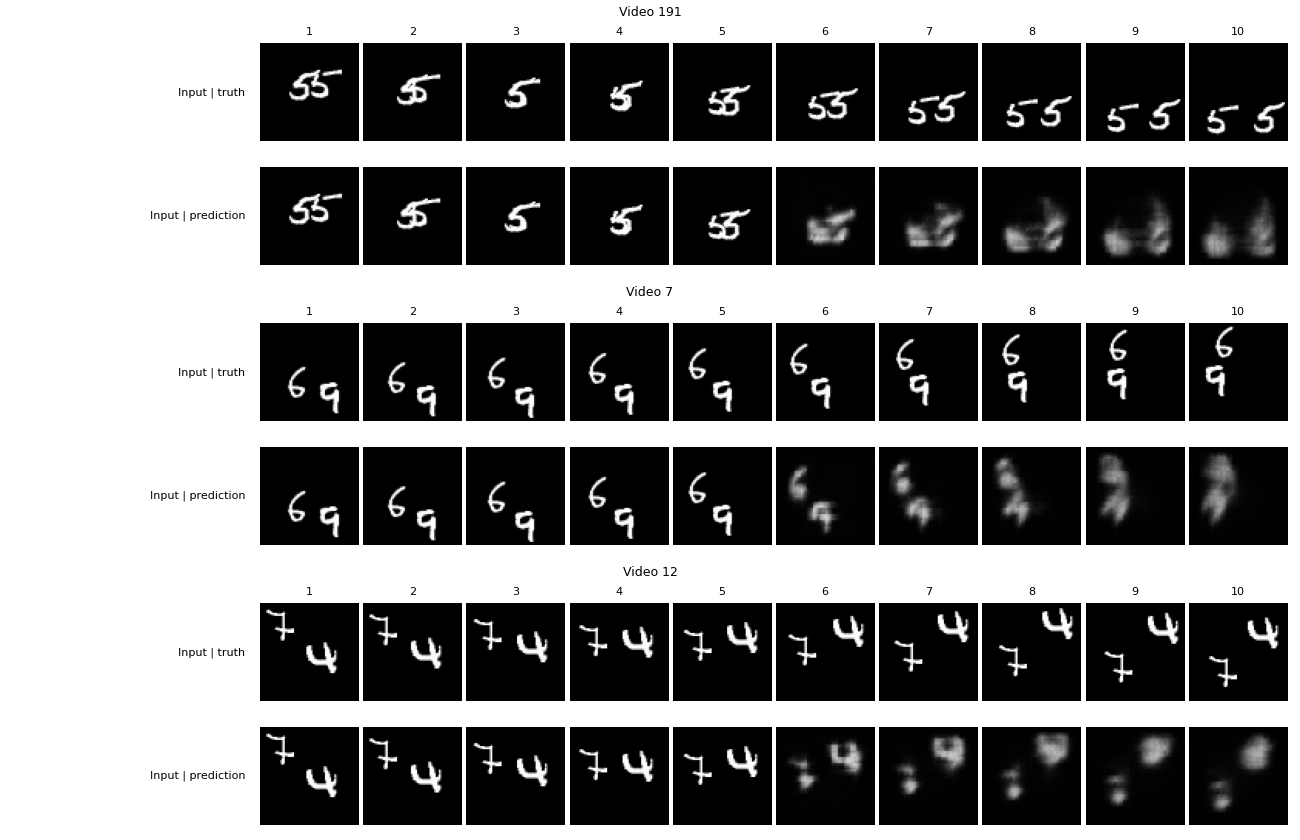

In [6]:
!python evaluate.py --table_2_only
!python figures.py --figure_2_only
display(Image("figures/figure_2.png"))

Pause for 2.5.

Hardware: Tesla T4
Evaluated A seed 0
Evaluated A seed 1
### Table 2

| Model | MSE1 | MSE2 | MSE3 | MSE4 | MSE5 | E(5) | Parameters |
|---|---|---|---|---|---|---|---|
| A | 0.0170 (0.0170, 0.0170) | 0.0205 (0.0206, 0.0203) | 0.0228 (0.0229, 0.0226) | 0.0245 (0.0247, 0.0243) | 0.0263 (0.0264, 0.0261) | 0.0222 (0.0223, 0.0221) | 480,784 |
| Blank | 0.0426 | 0.0426 | 0.0426 | 0.0425 | 0.0425 | 0.0426 | 0 |
| Copy-last | 0.0492 | 0.0604 | 0.0669 | 0.0708 | 0.0732 | 0.0641 | 0 |

### Table 3

| Model | E(5) | CM | EM | CR | ER |
|---|---|---|---|---|---|
| A | 0.0222 (0.0223, 0.0221) | 0.00204 (0.00200, 0.00208) | 0.0229 (0.0231, 0.0228) | 0.00319 (0.00340, 0.00298) | 0.0240 (0.0241, 0.0238) |
| Blank | 0.0426 | 0 | 0.0426 | 0 | 0.0426 |
| Copy-last | 0.0641 | 0 | 0.0641 | 0 | 0.0641 |

### Table 4

| Model | E(2) 1x | E(2) 2x | E(2) 3x | E(5) 1x | E(5) 2x |
|---|---|---|---|---|---|
| A | 0.0187 (0.0188, 0.0187) | 0.0454 (0.0463, 0.0445) | 0.0535 (0.0546, 0.0524) | 0.0222 (0.0223, 0.0221

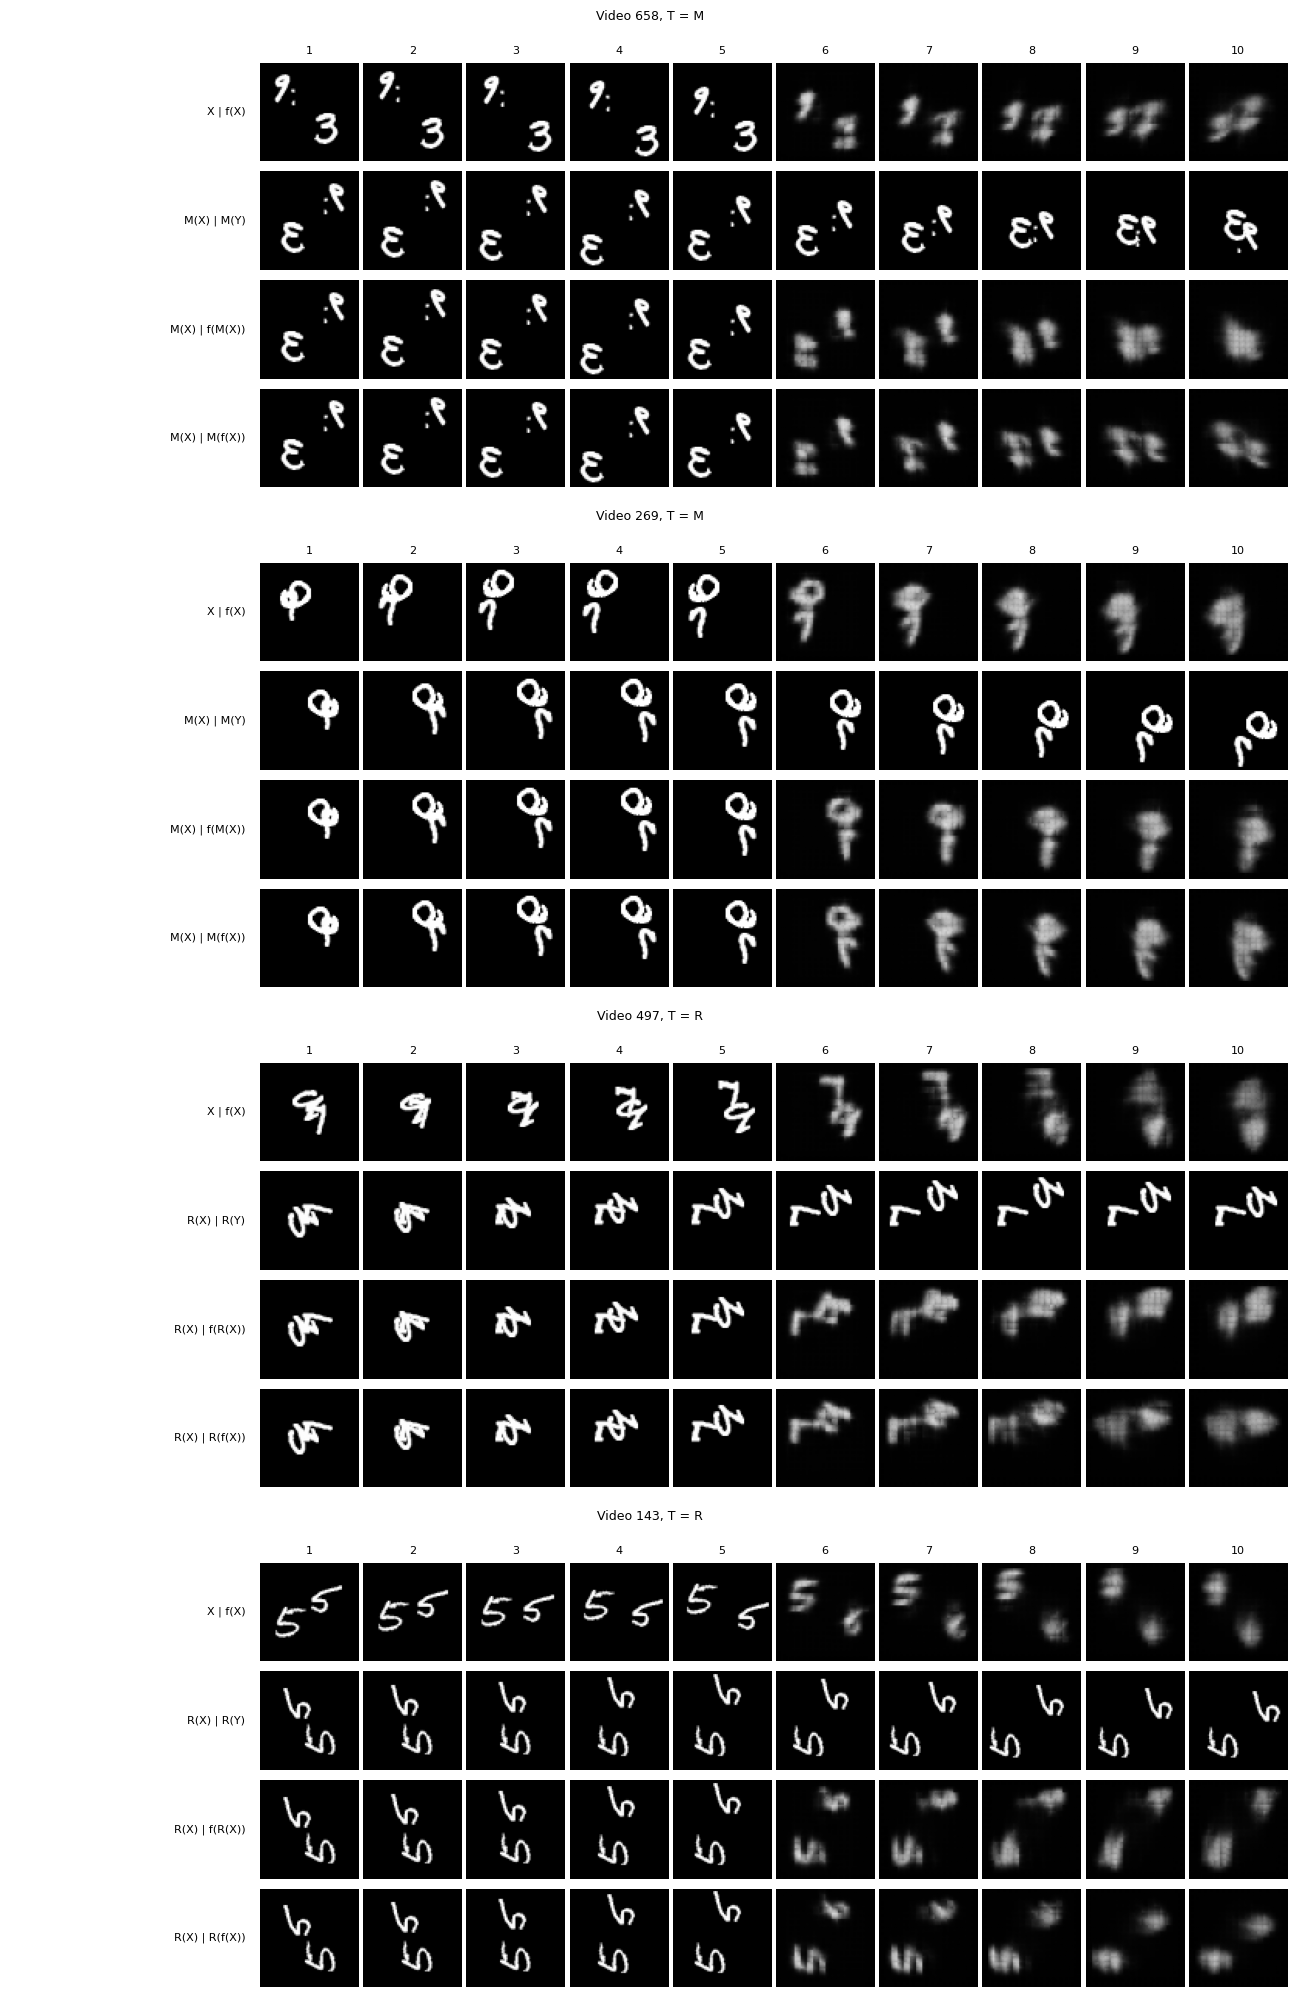

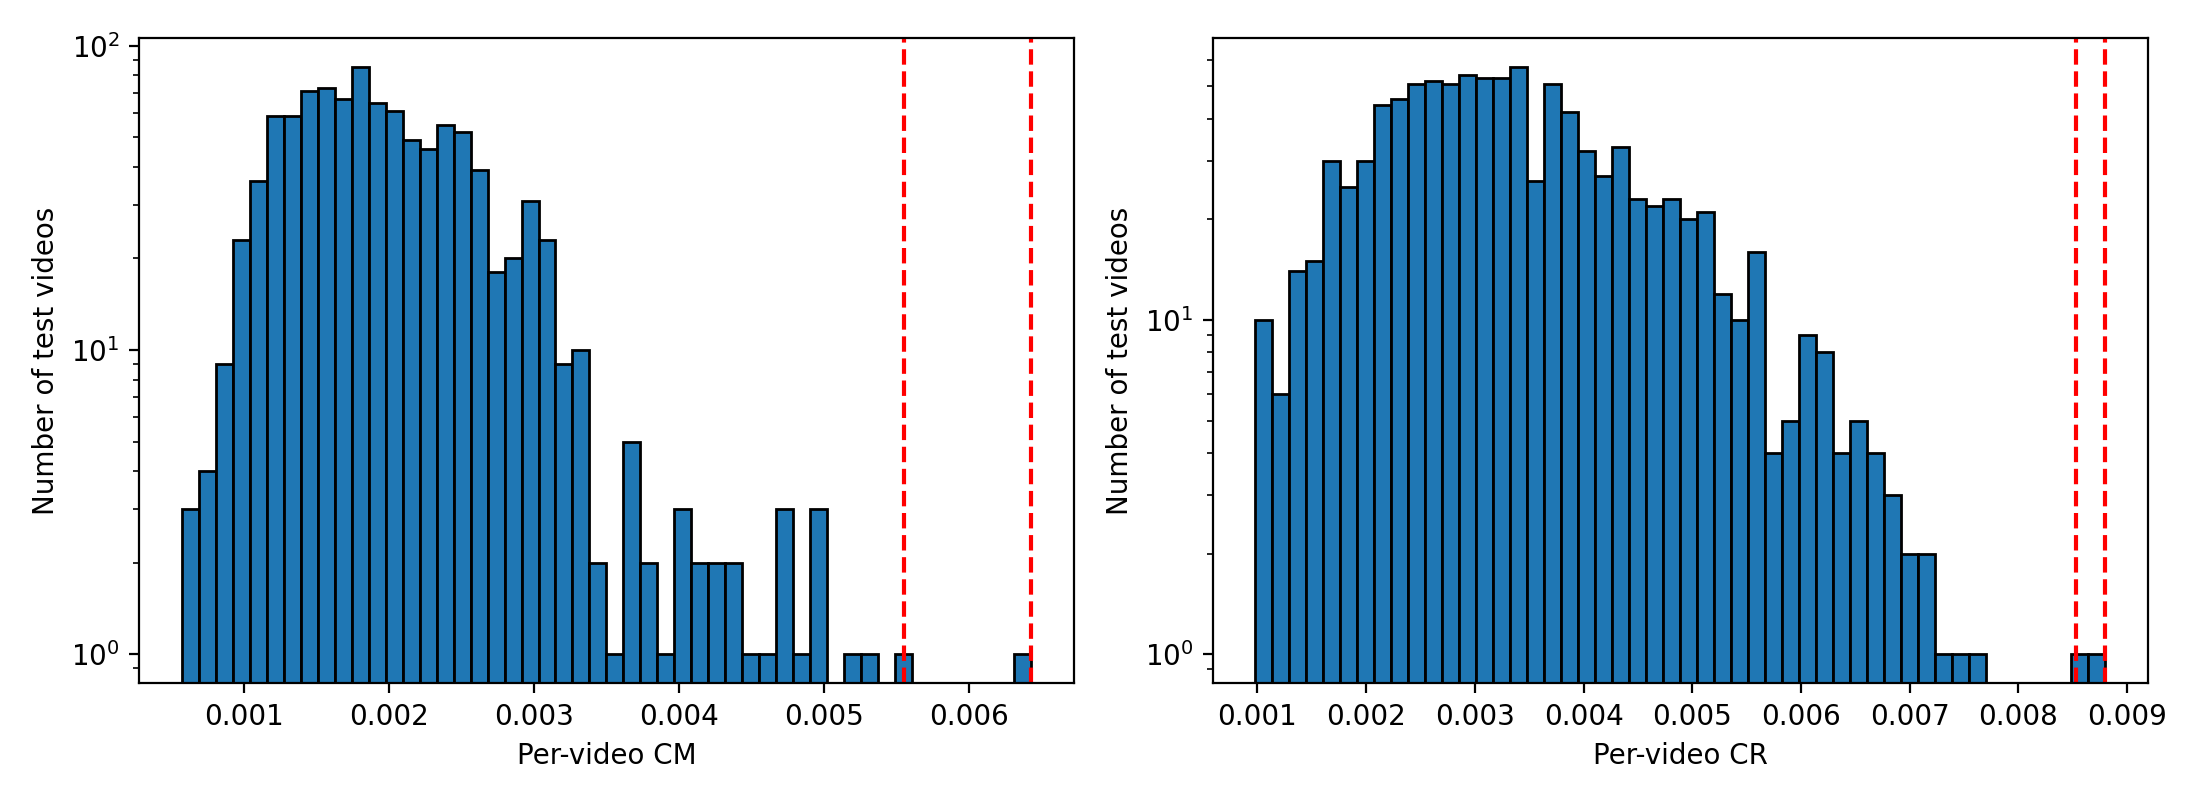

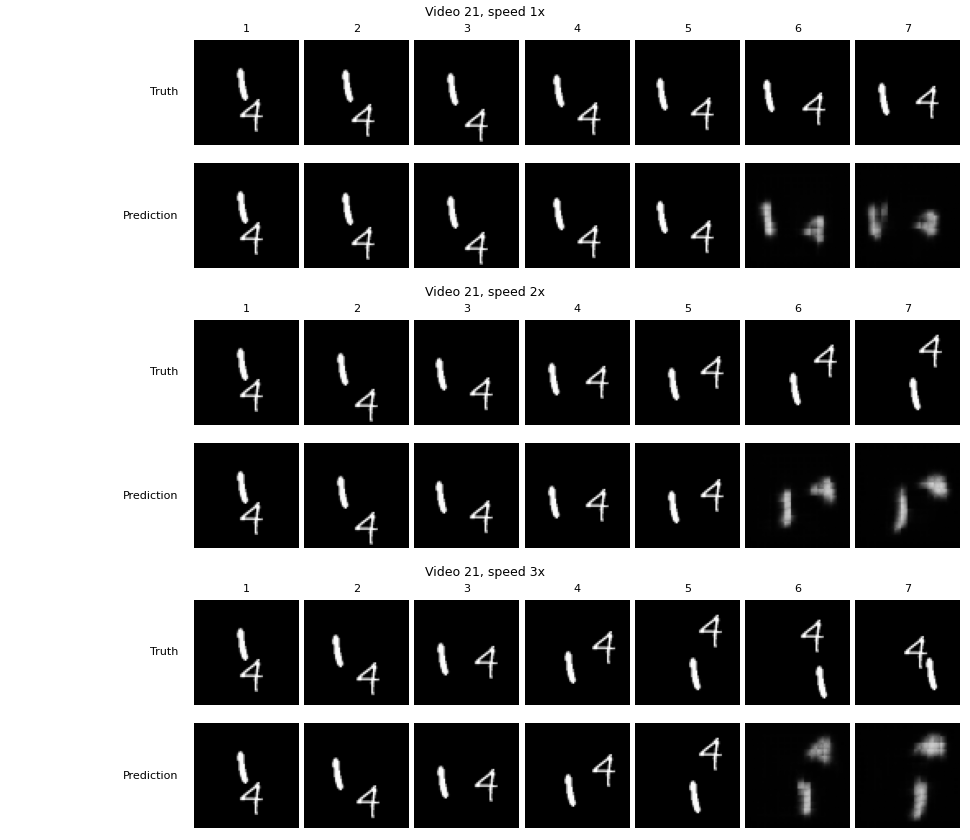

In [7]:
!python evaluate.py
!python figures.py
for name in ["figure_3", "figure_4", "figure_5"]:
    display(Image("figures/" + name + ".png"))

Pause for 2.11.

In [8]:
!python train.py --model D --design D1 --seed 0 --output_dir candidates_D1
!python train.py --model D --design D2 --seed 0 --output_dir candidates_D2
import torch
for name in ["D1", "D2"]:
    checkpoint = torch.load("candidates_" + name + "/D_seed0.pt", map_location = "cpu")
    print(name, checkpoint["validation_log"][-1])

Hardware: Tesla T4
Model D design D1 seed 0 parameters 594496
{"E2_1x": 0.0394083634018898, "E2_2x": 0.039382047951221466, "E2_3x": 0.039376839995384216, "epoch": 1, "train_loss": 0.04933493696153164} epoch time 4.5
{"E2_1x": 0.03911532089114189, "E2_2x": 0.0391414575278759, "E2_3x": 0.03918331116437912, "epoch": 2, "train_loss": 0.04000988344848156} epoch time 3.95
{"E2_1x": 0.03874105215072632, "E2_2x": 0.03881878778338432, "E2_3x": 0.03892878443002701, "epoch": 3, "train_loss": 0.03974896764755249} epoch time 3.97
{"E2_1x": 0.03829013928771019, "E2_2x": 0.03841862082481384, "E2_3x": 0.03860225901007652, "epoch": 4, "train_loss": 0.0394142377525568} epoch time 3.97
{"E2_1x": 0.037584636360406876, "E2_2x": 0.03783676400780678, "E2_3x": 0.03819964826107025, "epoch": 5, "train_loss": 0.038997871741652486} epoch time 3.97
{"E2_1x": 0.03679775074124336, "E2_2x": 0.03715777024626732, "E2_3x": 0.03767231106758118, "epoch": 6, "train_loss": 0.03844152688980103} epoch time 4.04
{"E2_1x": 0.03

In [9]:
!sed -i "s/^MODEL_D_DESIGN = .*/MODEL_D_DESIGN = \"D1\"/" model.py
!grep -n "^MODEL_D_DESIGN" model.py

11:MODEL_D_DESIGN = "D1"


In [10]:
for model_name in ["B", "C", "D"]:
    for seed in [0, 1]:
        !python train.py --model {model_name} --seed {seed}

Hardware: Tesla T4
Model B design baseline seed 0 parameters 480784
{"E2_1x": 0.03934269770979881, "E2_2x": 0.03934803977608681, "E2_3x": 0.039348434656858444, "epoch": 1, "train_loss": 0.04609318046271801} epoch time 10.73
{"E2_1x": 0.03845050930976868, "E2_2x": 0.038766007870435715, "E2_3x": 0.03893369063735008, "epoch": 2, "train_loss": 0.039731635212898256} epoch time 10.17
{"E2_1x": 0.03693760186433792, "E2_2x": 0.03795462101697922, "E2_3x": 0.03853107616305351, "epoch": 3, "train_loss": 0.038687665969133374} epoch time 10.22
{"E2_1x": 0.03477644547820091, "E2_2x": 0.03722897544503212, "E2_3x": 0.03839170187711716, "epoch": 4, "train_loss": 0.03724890697002411} epoch time 10.39
{"E2_1x": 0.032107386738061905, "E2_2x": 0.03650849685072899, "E2_3x": 0.03888489678502083, "epoch": 5, "train_loss": 0.03540220190584659} epoch time 10.5
{"E2_1x": 0.029834065586328506, "E2_2x": 0.03622504323720932, "E2_3x": 0.039837226271629333, "epoch": 6, "train_loss": 0.033661220639944076} epoch time 1

In [11]:
for seed in [0, 1]:
    !python train.py --model DB --seed {seed}

Hardware: Tesla T4
Model DB design D1 seed 0 parameters 594496
{"E2_1x": 0.039393991231918335, "E2_2x": 0.039365265518426895, "E2_3x": 0.039358239620923996, "epoch": 1, "train_loss": 0.049277087867259976} epoch time 5.14
{"E2_1x": 0.03923802077770233, "E2_2x": 0.039210136979818344, "E2_3x": 0.03920327126979828, "epoch": 2, "train_loss": 0.040018126651644705} epoch time 4.58
{"E2_1x": 0.039074692875146866, "E2_2x": 0.03904716670513153, "E2_3x": 0.03904065862298012, "epoch": 3, "train_loss": 0.03984593433141708} epoch time 4.57
{"E2_1x": 0.038909927010536194, "E2_2x": 0.03888269513845444, "E2_3x": 0.03887614235281944, "epoch": 4, "train_loss": 0.03968945348262787} epoch time 4.53
{"E2_1x": 0.0387384407222271, "E2_2x": 0.0387224406003952, "E2_3x": 0.03871816396713257, "epoch": 5, "train_loss": 0.039517829224467275} epoch time 4.62
{"E2_1x": 0.03861737996339798, "E2_2x": 0.03859023377299309, "E2_3x": 0.03858382627367973, "epoch": 6, "train_loss": 0.039366358771920205} epoch time 4.54
{"E2_

Hardware: Tesla T4
Evaluated A seed 0
Evaluated A seed 1
Evaluated B seed 0
Evaluated B seed 1
Evaluated C seed 0
Evaluated C seed 1
Evaluated D seed 0
Evaluated D seed 1
Evaluated DB seed 0
Evaluated DB seed 1
### Table 2

| Model | MSE1 | MSE2 | MSE3 | MSE4 | MSE5 | E(5) | Parameters |
|---|---|---|---|---|---|---|---|
| A | 0.0170 (0.0170, 0.0170) | 0.0205 (0.0206, 0.0203) | 0.0228 (0.0229, 0.0226) | 0.0245 (0.0247, 0.0243) | 0.0263 (0.0264, 0.0261) | 0.0222 (0.0223, 0.0221) | 480,784 |
| Blank | 0.0426 | 0.0426 | 0.0426 | 0.0425 | 0.0425 | 0.0426 | 0 |
| Copy-last | 0.0492 | 0.0604 | 0.0669 | 0.0708 | 0.0732 | 0.0641 | 0 |

### Table 3

| Model | E(5) | CM | EM | CR | ER |
|---|---|---|---|---|---|
| A | 0.0222 (0.0223, 0.0221) | 0.00204 (0.00200, 0.00208) | 0.0229 (0.0231, 0.0228) | 0.00319 (0.00340, 0.00298) | 0.0240 (0.0241, 0.0238) |
| Blank | 0.0426 | 0 | 0.0426 | 0 | 0.0426 |
| Copy-last | 0.0641 | 0 | 0.0641 | 0 | 0.0641 |

### Table 4

| Model | E(2) 1x | E(2) 2x | E(2) 3x 

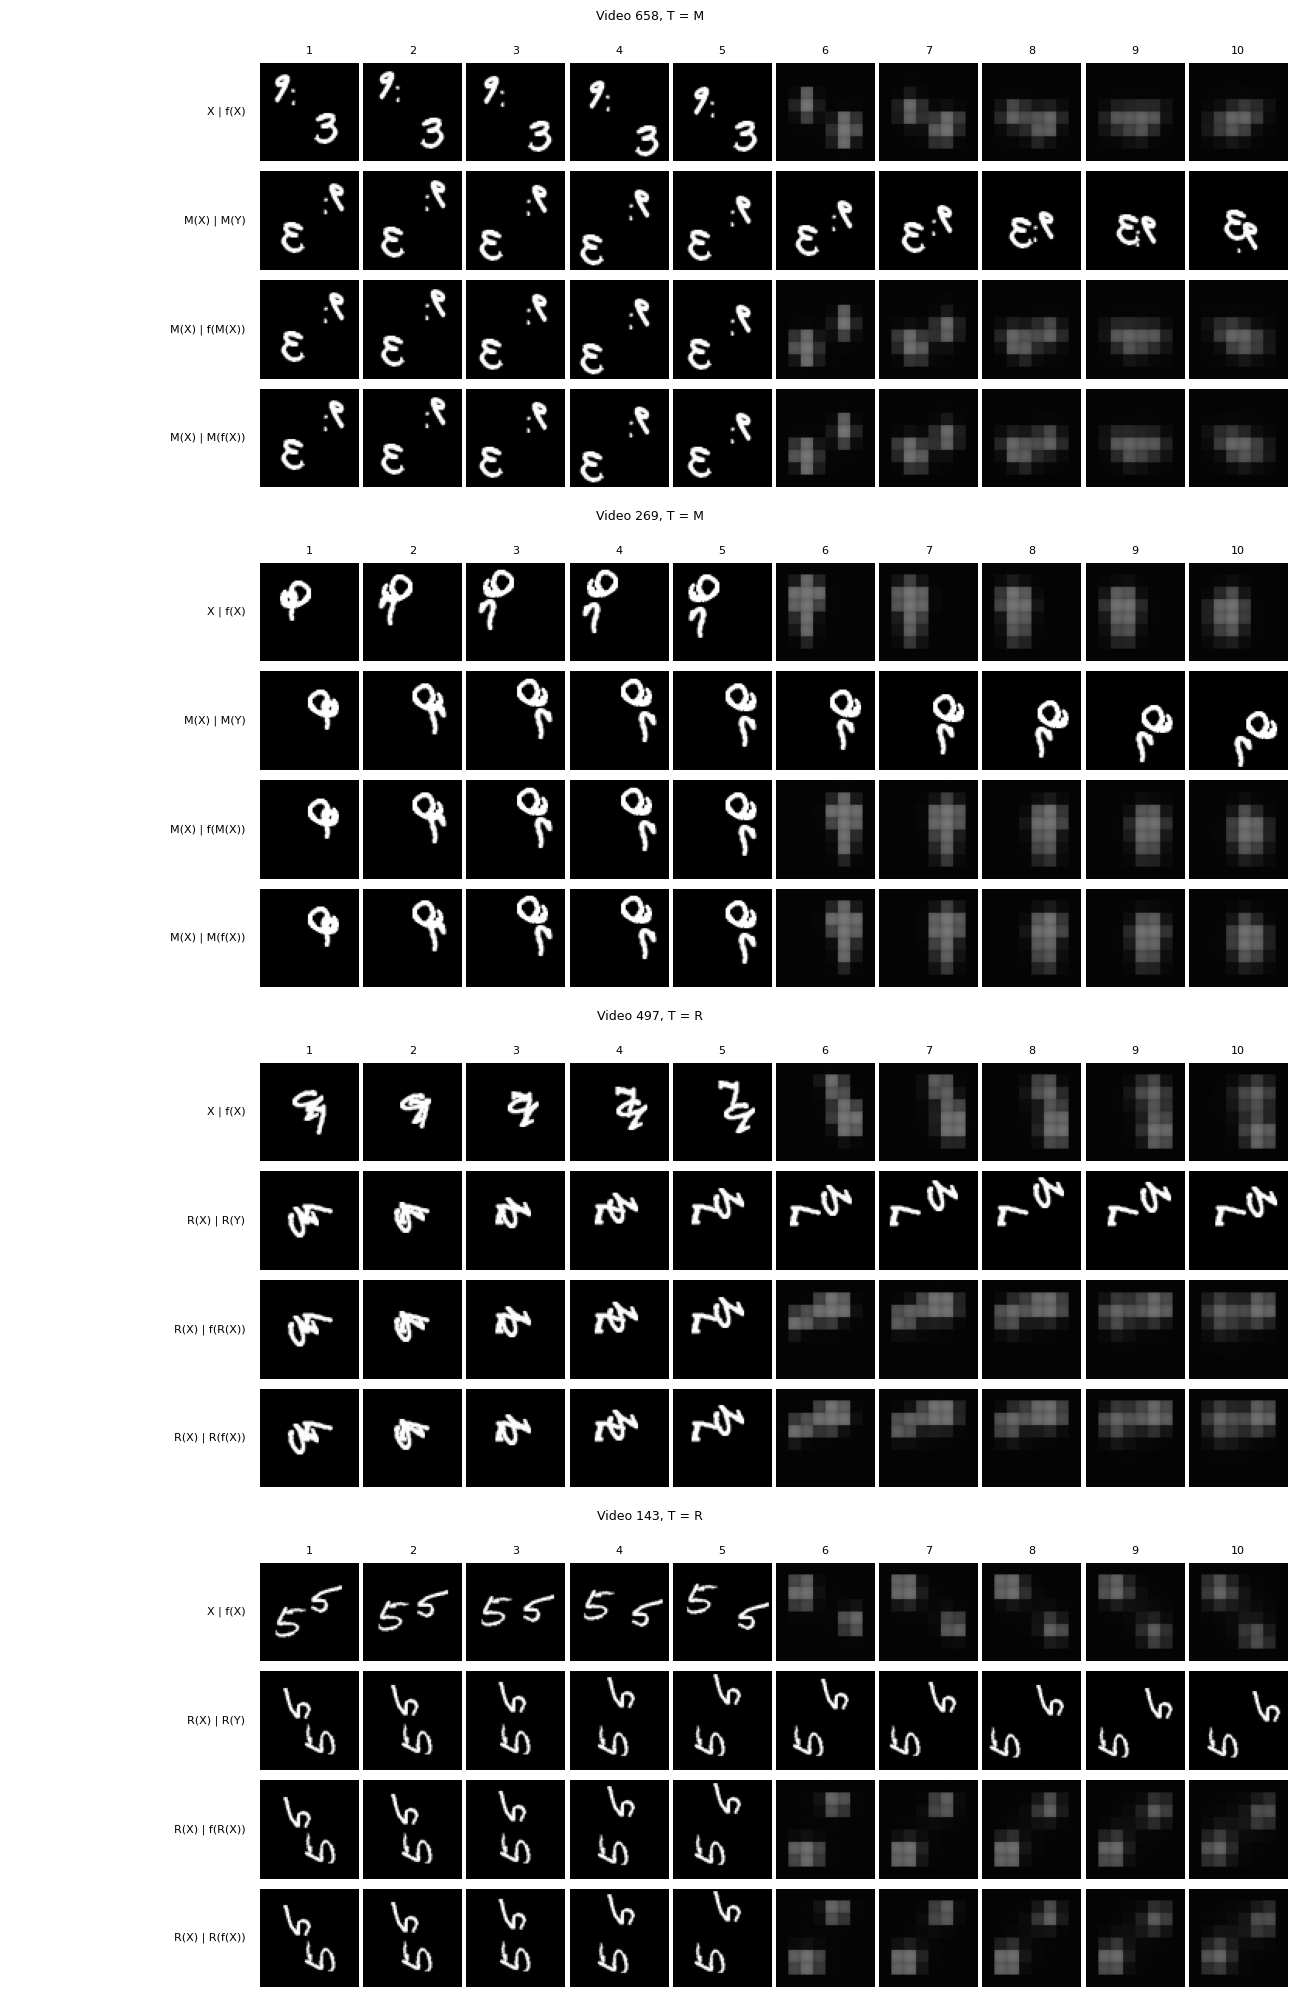

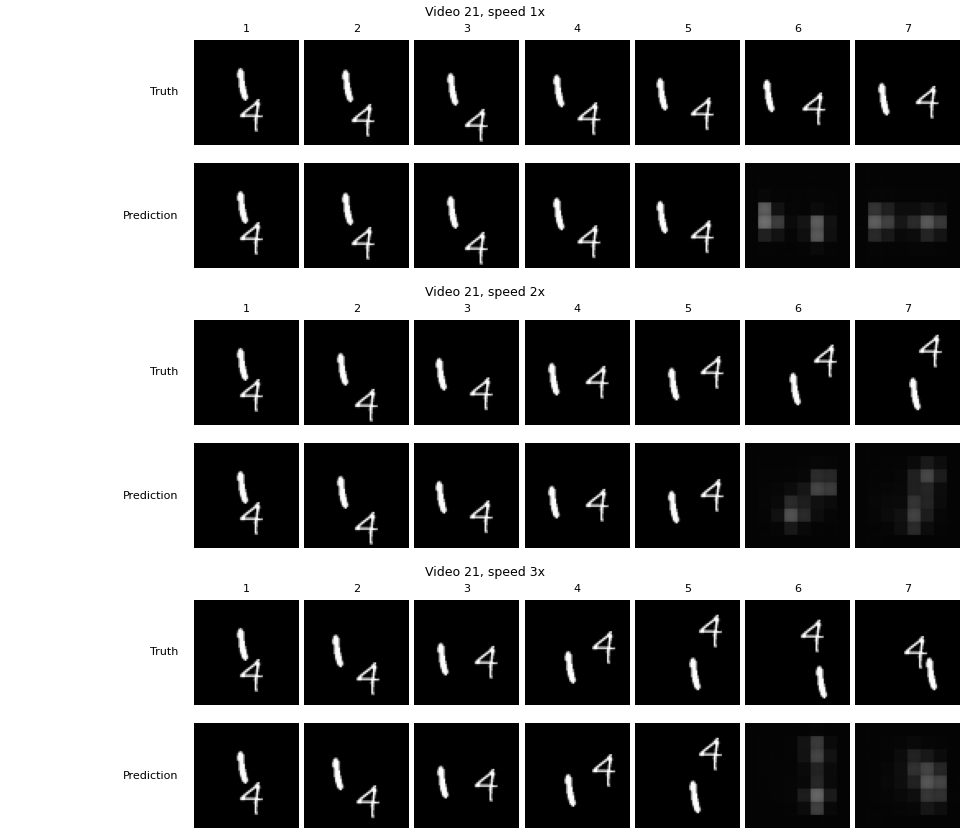

In [12]:
!python evaluate.py
!python figures.py --final_model D
print(open("results/tables.md").read())
for name in ["figure_6a", "figure_6b"]:
    display(Image("figures/" + name + ".png"))

In [13]:
!zip -qr PA2_outputs.zip checkpoints results figures candidates_D1 candidates_D2